# O que faz a operação de shows de um grupo de K-pop ser lucrativa?
**Análise exploratória — dados simulados (`kpop_shows.csv`)**

> **Aviso.** Nomes de grupos e integrantes são reais; **todos** os shows, públicos, preços, receitas, custos e lucros são **simulados para ensino**. Nenhuma conclusão vale como fato sobre pessoas ou organizações reais.

**Roteiro:** 1) contexto e unidade de análise → 2) carga, inspeção e limpeza → 3) perguntas específicas (tabelas, gráficos, n e medidas) → 4) insights, ações e como avaliá-las → 5) limitações.

## 1. Contextualização e unidade de análise
- **Pergunta ampla:** o que faz a *operação dos shows* de um grupo ser lucrativa? Não é o lucro da banda/agência: não há streaming, discos, licenciamento nem custos corporativos.
- **Unidade de análise:** 1 linha = 1 show programado (1.902 shows, 20 grupos, 180 turnês, 2023–2025), **incluindo 24 cancelados**, que mantêm custos já incorridos.
- **Perspectiva financeira:** operação consolidada do evento. O **repasse aos artistas é custo** da operação (não prejuízo dos artistas).
- **Medidas de desempenho:** **lucro operacional (USD)** para escala e **margem = lucro / receita total** para comparar shows de tamanhos diferentes. Nos cancelados a receita é zero, então a margem só existe nos realizados; os cancelados entram no lucro total e na análise por turnê.
- **Não-independência:** shows da mesma turnê/grupo compartilham características. Por isso os modelos usam **erros-padrão clusterizados por turnê** (e por grupo como checagem), e também comparo em nível de turnê e de grupo.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 60)
pd.options.display.float_format = '{:,.3f}'.format
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})

## 2. Carga, inspeção e limpeza

In [2]:
# O CSV está embutido neste notebook: não precisa fazer upload.
import os, base64, gzip
ARQ = 'kpop_shows.csv'
_CSV_GZ_B64 = (
    "..."
    "AA=="
)
if not os.path.exists(ARQ):
    open(ARQ, 'wb').write(gzip.decompress(base64.b64decode(_CSV_GZ_B64)))
k = pd.read_csv(ARQ, encoding='utf-8-sig', parse_dates=['data_show'])
print(k.shape)
k.head(3)

(1902, 48)


,id_show,dados_simulados,grupo,integrante_referencia,ano_estreia_grupo,data_show,ano,id_turne,ordem_show_turne,shows_planejados_turne,pais,cidade,regiao,moeda,cambio_moeda_local_por_usd,tipo_local,capacidade,publico_pagante,cortesias,status_show,preco_medio_efetivo_moeda_local,desconto_medio_pct,antecedencia_venda_dias,dias_desde_lancamento,seguidores_locais_milhoes,engajamento_redes_pct,streams_locais_30_dias_milhoes,padrao_producao,intervalo_show_anterior_dias,mesmo_pais_show_anterior,receita_ingressos_usd,receita_produtos_usd,receita_patrocinio_usd,custo_aluguel_usd,custo_producao_usd,custo_equipe_usd,custo_transporte_usd,custo_hospedagem_usd,custo_marketing_usd,custo_produtos_usd,repasse_artistas_usd,comissao_promotor_usd,impostos_usd,rateio_abertura_turne_usd,receita_total_usd,custo_total_usd,lucro_operacional_usd,satisfacao_publico_0a10
0,K00001,True,TWICE,Jihyo,2015,2023-02-02,2023,T01-2023-1,1,8,Filipinas,Manila,Asia,PHP,52.526,arena,8000,7920,80,realizado,"2,880.440",0.000,70,157,14.630,4.110,40.920,essencial,NaN,False,"434,315.890","67,798.200","21,641.180","18,885.520","14,106.030","13,417.890","10,134.350","7,807.560","54,473.490","31,141.860","54,022.940","43,156.840","32,674.040","12,555.790","523,755.270","292,376.310","231,378.960",8.000
1,K00002,True,TWICE,Jihyo,2015,2023-02-05,2023,T01-2023-1,2,8,Filipinas,Manila,Asia,PHP,54.737,estadio,35000,34650,350,realizado,"3,309.070",0.000,128,160,14.470,6.010,37.770,essencial,3.000,True,"2,094,718.480","239,561.090","22,774.490","52,793.620","28,931.890","14,641.250","1,928.670","10,906.930","65,081.420","91,751.780","268,334.080","198,778.530","226,494.080","12,555.790","2,357,054.060","972,198.040","1,384,856.020",8.500
2,K00003,True,TWICE,Jihyo,2015,2023-02-08,2023,T01-2023-1,3,8,Filipinas,Manila,Asia,PHP,58.139,arena,22000,21780,220,realizado,"4,115.120",10.000,101,163,11.610,4.000,39.100,essencial,3.000,True,"1,541,614.050","117,776.670",63.480,"29,685.380","19,013.310","15,262.140","2,157.740","11,685.830","86,207.860","48,788.280","179,820.490","199,192.560","68,062.840","12,555.790","1,659,454.200","672,432.220","987,021.980",7.200


In [3]:
# Dados ausentes (célula vazia = ausente, NÃO zero) e duplicidades
aus = k.isna().sum(); aus = aus[aus > 0].to_frame('ausentes'); aus['%'] = aus.ausentes / len(k) * 100
display(aus)
print('id_show duplicado:', k.id_show.duplicated().sum(), '| linhas 100% duplicadas:', k.duplicated().sum())
print(k.status_show.value_counts().to_dict())

,ausentes,%
seguidores_locais_milhoes,67,3.523
streams_locais_30_dias_milhoes,58,3.049
intervalo_show_anterior_dias,180,9.464
satisfacao_publico_0a10,88,4.627


id_show duplicado: 0 | linhas 100% duplicadas: 0
{'realizado': 1878, 'cancelado': 24}


**Leitura dos ausentes.** `intervalo_show_anterior_dias` é ausente por construção na 1ª data de cada turnê (180 turnês = 180 ausências). `satisfacao_publico_0a10` falta nos cancelados (24) e em parte dos realizados. `seguidores_locais_milhoes` (≈3,5%) e `streams_locais_30_dias_milhoes` (≈3%) têm medição incompleta. **Não imputo zero**: os modelos usam casos completos e informo o n; essas colunas só entram onde são necessárias.

In [4]:
# Padronização de texto: cidades com diferenças de caixa/espaços
print('cidades antes:', k.cidade.nunique())
k['cidade'] = k.cidade.str.strip().str.title()
print('cidades depois:', k.cidade.nunique())

# Conferência contábil: componentes batem com os totais fornecidos?
rec = ['receita_ingressos_usd','receita_produtos_usd','receita_patrocinio_usd']
cus = ['custo_aluguel_usd','custo_producao_usd','custo_equipe_usd','custo_transporte_usd','custo_hospedagem_usd',
       'custo_marketing_usd','custo_produtos_usd','repasse_artistas_usd','comissao_promotor_usd','impostos_usd','rateio_abertura_turne_usd']
print('max |receita - soma|:', (k[rec].sum(axis=1)-k.receita_total_usd).abs().max())
print('max |custo - soma|  :', (k[cus].sum(axis=1)-k.custo_total_usd).abs().max())
print('max |lucro - (R-C)| :', (k.receita_total_usd-k.custo_total_usd-k.lucro_operacional_usd).abs().max())

# Turnês: o nº de linhas bate com o planejado (cancelados inclusos)?
t_chk = k.groupby('id_turne').agg(linhas=('id_show','size'), plan=('shows_planejados_turne','first'))
print('turnês:', len(t_chk), '| com linhas != planejado:', (t_chk.linhas != t_chk.plan).sum())

cidades antes: 31
cidades depois: 18
max |receita - soma|: 9.313225746154785e-10
max |custo - soma|  : 4.656612873077393e-10
max |lucro - (R-C)| : 4.656612873077393e-10
turnês: 180 | com linhas != planejado: 0


**Câmbio e preço.** O preço está em moeda local e `cambio_moeda_local_por_usd` diz quantas unidades locais compram 1 USD. Comparar o preço bruto entre países seria enganoso (ex.: IDR vs USD). Converto: `preco_usd = preco_local / câmbio`, e valido: `público × preco_usd` deve reproduzir `receita_ingressos_usd`.

In [5]:
k['preco_usd'] = k.preco_medio_efetivo_moeda_local / k.cambio_moeda_local_por_usd
k['ocup'] = k.publico_pagante / k.capacidade                       # taxa de ocupação paga
k['margem'] = np.where(k.receita_total_usd > 0, k.lucro_operacional_usd / k.receita_total_usd, np.nan)

r = k[k.status_show == 'realizado'].copy()                         # shows realizados
r['log_seg'] = np.log(r.seguidores_locais_milhoes)
razao = (r.publico_pagante * r.preco_usd) / r.receita_ingressos_usd
print('público×preço_usd / receita_ingressos -> min/mediana/max:', razao.min().round(6), razao.median().round(6), razao.max().round(6))
print('Preço mediano em USD por moeda:'); display(r.groupby('moeda').preco_usd.median().sort_values().round(1).to_frame('preco_usd_mediano').T)
print('Ocupação máx =', r.ocup.max(), '| fração de shows no teto de 99%:', round((r.ocup.round(2)==0.99).mean(), 3))

público×preço_usd / receita_ingressos -> min/mediana/max: 1.0 1.0 1.0
Preço mediano em USD por moeda:


moeda,IDR,PHP,BRL,THB,MXN,CLP,KRW,JPY,EUR,GBP,CAD,SGD,USD
preco_usd_mediano,51.200,51.400,58.400,61.800,65.700,66.700,88.900,102.300,103.400,115.600,115.800,122.600,128.200


Ocupação máx = 0.99 | fração de shows no teto de 99%: 0.565


**Decisões de limpeza (justificadas).**
1. Câmbio: a razão ≈ 1,0 confirma que `preco_usd` está correto e que **o preço já é efetivo (pós-desconto)** — não descontei de novo.
2. Cidades: 31 grafias → 18 cidades reais (só caixa/espaços).
3. A ocupação tem **teto em 99%** (muita massa em 0,99): é um limite de venda, então é uma variável *censurada*; evito interpretá-la como linear nos extremos.
4. Cancelados ficam na base (receita 0, custos incorridos). Para margem uso só realizados (`r`); para lucro total/turnê uso todos.
5. Ausentes nunca viram zero; modelos usam casos completos e informo n.

## 3. Perguntas específicas
### Q1. Onde está o dinheiro? Composição de receitas e custos (realizados)

In [6]:
comp = pd.DataFrame({'USD (milhões)': pd.concat([r[rec].sum(), r[cus].sum()]) / 1e6})
comp['% da receita total'] = comp['USD (milhões)'] / (r.receita_total_usd.sum()/1e6) * 100
comp['tipo'] = ['receita']*3 + ['custo']*len(cus)
display(comp.sort_values(['tipo','USD (milhões)'], ascending=[False, False]).round(2))
print(f'n realizados = {len(r)} | receita {r.receita_total_usd.sum()/1e6:,.0f} M | custo {r.custo_total_usd.sum()/1e6:,.0f} M | lucro {r.lucro_operacional_usd.sum()/1e6:,.0f} M | margem agregada {r.lucro_operacional_usd.sum()/r.receita_total_usd.sum():.1%}')
var = ['repasse_artistas_usd','comissao_promotor_usd','impostos_usd','custo_produtos_usd']
print(f'Custos que escalam com a receita (repasse+comissão+impostos+produtos): {r[var].sum().sum()/r.custo_total_usd.sum():.0%} do custo total')

,USD (milhões),% da receita total,tipo
receita_ingressos_usd,"2,060.530",84.920,receita
receita_produtos_usd,333.520,13.750,receita
receita_patrocinio_usd,32.330,1.330,receita
comissao_promotor_usd,247.530,10.200,custo
repasse_artistas_usd,246.930,10.180,custo
impostos_usd,158.170,6.520,custo
custo_produtos_usd,126.500,5.210,custo
custo_marketing_usd,103.210,4.250,custo
custo_aluguel_usd,99.360,4.090,custo
custo_producao_usd,97.570,4.020,custo


n realizados = 1878 | receita 2,426 M | custo 1,228 M | lucro 1,199 M | margem agregada 49.4%
Custos que escalam com a receita (repasse+comissão+impostos+produtos): 63% do custo total


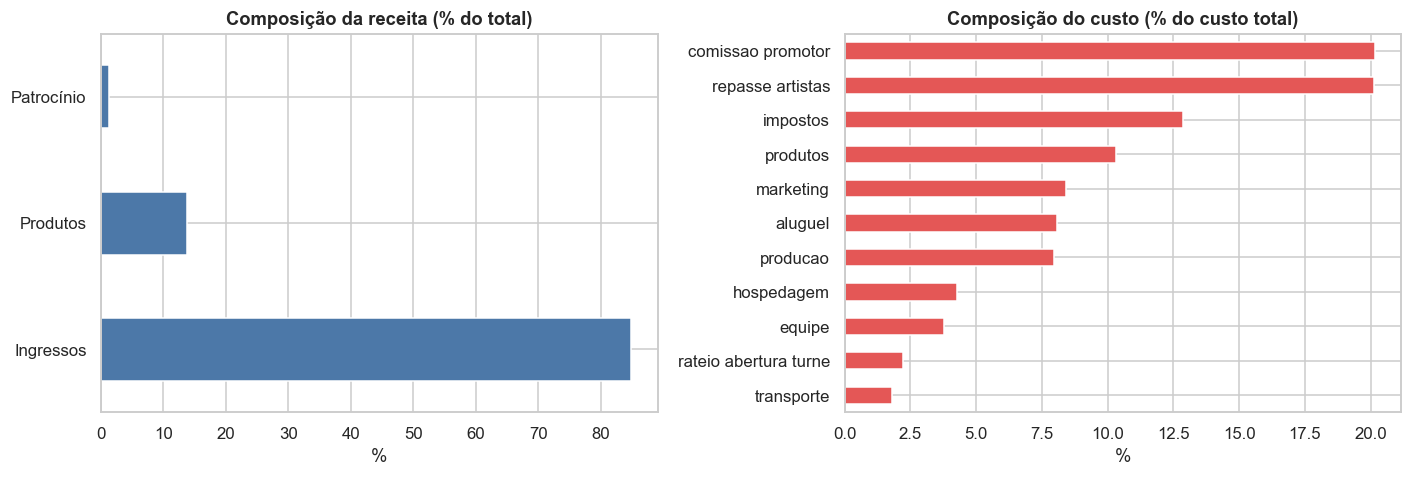

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
rv = (r[rec].sum()/r.receita_total_usd.sum()*100); rv.index = ['Ingressos','Produtos','Patrocínio']
rv.plot.barh(ax=ax[0], color='#4C78A8'); ax[0].set_title('Composição da receita (% do total)'); ax[0].set_xlabel('%')
cv = (r[cus].sum()/r.custo_total_usd.sum()*100).sort_values()
cv.index = [i.replace('_usd','').replace('custo_','').replace('_',' ') for i in cv.index]
cv.plot.barh(ax=ax[1], color='#E45756'); ax[1].set_title('Composição do custo (% do custo total)'); ax[1].set_xlabel('%')
plt.tight_layout(); plt.show()

**Leitura.** Ingressos ≈ 85% da receita; patrocínio é marginal (~1%). Cerca de 63% do custo (repasse, comissão, impostos, produtos) **escala com a receita**; portanto, o que diferencia a lucratividade entre shows é **receita versus os custos mais fixos** (aluguel, produção, equipe, hospedagem, rateio). *Explicação alternativa:* isso é em parte a estrutura contratual simulada, não algo manipulável.

### Q2. Cancelamentos pesam na operação da turnê?

In [8]:
canc = k[k.status_show == 'cancelado']
print(f'cancelados: {len(canc)} de {len(k)} ({len(canc)/len(k):.1%}) | custo incorrido: {canc.custo_total_usd.sum()/1e6:.2f} M USD')
print(f'lucro total da base (todos os shows): {k.lucro_operacional_usd.sum()/1e6:,.0f} M | sem cancelamentos seria {canc.custo_total_usd.sum()/(k.lucro_operacional_usd.sum()+canc.custo_total_usd.sum()):.2%} maior')

turne = k.groupby('id_turne').agg(grupo=('grupo','first'), ano=('ano','first'), shows=('id_show','size'),
        cancelados=('status_show', lambda s: (s=='cancelado').sum()), receita=('receita_total_usd','sum'),
        custo=('custo_total_usd','sum'), lucro=('lucro_operacional_usd','sum'))
turne['margem'] = turne.lucro / turne.receita
turne['teve_cancelamento'] = turne.cancelados > 0
print('turnês:', len(turne), '| com prejuízo:', (turne.lucro < 0).sum(), '| com cancelamento:', turne.teve_cancelamento.sum(), '| máx cancelamentos por turnê:', turne.cancelados.max())
display(turne.groupby('teve_cancelamento').agg(n_turnes=('lucro','size'), margem_mediana=('margem','median'), lucro_mediano=('lucro','median')).round(3))
tx = k.groupby('regiao').apply(lambda d: pd.Series({'n': len(d), 'cancelados': (d.status_show=='cancelado').sum(), 'taxa': (d.status_show=='cancelado').mean()}), include_groups=False)
display(tx.round(4))

cancelados: 24 de 1902 (1.3%) | custo incorrido: 3.43 M USD
lucro total da base (todos os shows): 1,195 M | sem cancelamentos seria 0.29% maior
turnês: 180 | com prejuízo: 0 | com cancelamento: 24 | máx cancelamentos por turnê: 1


,n_turnes,margem_mediana,lucro_mediano
teve_cancelamento,,,
False,156,0.487,"5,633,831.195"
True,24,0.442,"4,366,760.555"


,n,cancelados,taxa
regiao,,,
America Latina,429.000,7.000,0.016
America do Norte,518.000,3.000,0.006
Asia,443.000,8.000,0.018
Europa,512.000,6.000,0.012


**Leitura.** 24 cancelamentos (1,3% dos shows; no máximo 1 por turnê) custaram ~US$ 3,4 M, ≈ 0,3% do lucro total: **pouco material para o resultado agregado**, mas é perda líquida pura. Com n=24 não dá para atribuir causa por região ou tipo de local; é descritivo. Nenhuma das 180 turnês termina no prejuízo.

### Q3. O tamanho do local está ajustado à demanda?
Hipótese: a lucratividade por show depende de combinar **capacidade** com a **demanda esperada**, medida *antes* do evento (seguidores locais, engajamento, streams).

In [9]:
tl = r.groupby('tipo_local').agg(n=('margem','size'), capacidade_mediana=('capacidade','median'), ocup_mediana=('ocup','median'),
        preco_usd_mediano=('preco_usd','median'), margem_mediana=('margem','median'), lucro_mediano=('lucro_operacional_usd','median'))
print('Ocupação e margem por tipo de local (realizados):'); display(tl.round(3))

# demanda antecipada: terços de seguidores locais (casos com seguidores observados)
rs = r.dropna(subset=['seguidores_locais_milhoes']).copy()
rs['demanda'] = pd.qcut(rs.seguidores_locais_milhoes, 3, labels=['baixa','média','alta'])
print(f'n com seguidores observados: {len(rs)} de {len(r)} | cortes (milhões):', rs.groupby('demanda', observed=True).seguidores_locais_milhoes.agg(['min','max']).round(1).to_dict('index'))
g3 = rs.groupby(['demanda','tipo_local'], observed=True)
tab = g3.agg(n=('margem','size'), ocup_mediana=('ocup','median'), margem_mediana=('margem','median'), lucro_mediano=('lucro_operacional_usd','median'))
tab['margem_agregada'] = g3.apply(lambda d: d.lucro_operacional_usd.sum()/d.receita_total_usd.sum(), include_groups=False)
display(tab.round(3))

Ocupação e margem por tipo de local (realizados):


,n,capacidade_mediana,ocup_mediana,preco_usd_mediano,margem_mediana,lucro_mediano
tipo_local,,,,,,
arena,1286,"16,000.000",0.990,97.121,0.497,"594,053.935"
estadio,208,"35,000.000",0.430,101.434,0.474,"974,304.820"
teatro,384,"5,000.000",0.990,86.620,0.278,"106,980.350"


n com seguidores observados: 1811 de 1878 | cortes (milhões): {'baixa': {'min': 1.2, 'max': 6.6}, 'média': {'min': 6.6, 'max': 10.6}, 'alta': {'min': 10.6, 'max': 22.4}}


n  ocup_mediana  margem_mediana  lucro_mediano  margem_agregada
demanda tipo_local                                                                   
baixa   arena       353         0.575           0.380    258,859.660            0.395
        estadio      47         0.221           0.205    185,751.180            0.286
        teatro      205         0.990           0.232     78,026.950            0.261
média   arena       434         0.990           0.499    610,219.360            0.508
        estadio      87         0.418           0.473    978,757.190            0.481
        teatro       81         0.990           0.341    128,606.640            0.349
alta    arena       475         0.990           0.539    909,037.280            0.550
        estadio      71         0.603           0.538  1,384,856.020            0.551
        teatro       58         0.990           0.344    199,188.895            0.384

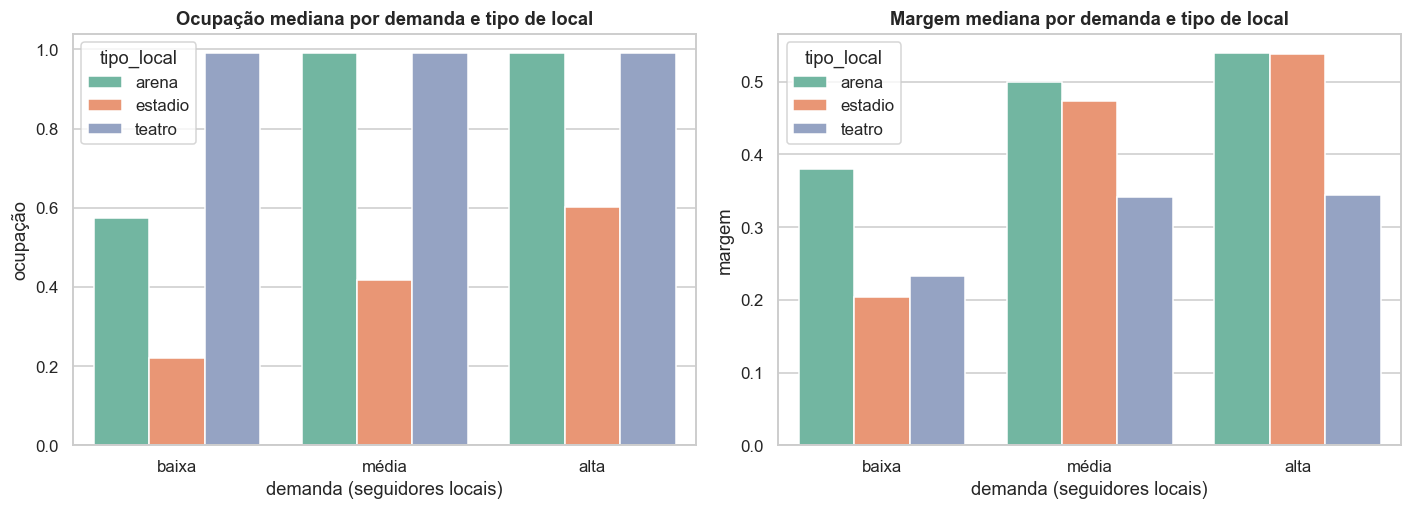

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sns.barplot(data=rs, x='demanda', y='ocup', hue='tipo_local', estimator=np.median, errorbar=None, ax=ax[0], palette='Set2')
ax[0].set_title('Ocupação mediana por demanda e tipo de local'); ax[0].set_ylabel('ocupação'); ax[0].set_xlabel('demanda (seguidores locais)')
sns.barplot(data=rs, x='demanda', y='margem', hue='tipo_local', estimator=np.median, errorbar=None, ax=ax[1], palette='Set2')
ax[1].set_title('Margem mediana por demanda e tipo de local'); ax[1].set_ylabel('margem'); ax[1].set_xlabel('demanda (seguidores locais)')
plt.tight_layout(); plt.show()

In [11]:
# O que prevê ocupação? Fatores pré-evento, erros-padrão clusterizados por turnê. n = casos completos.
cols = ['ocup','desconto_medio_pct','antecedencia_venda_dias','dias_desde_lancamento','engajamento_redes_pct','seguidores_locais_milhoes',
        'streams_locais_30_dias_milhoes','preco_usd','padrao_producao','tipo_local','regiao','id_turne']
d = r.dropna(subset=cols).copy()
m_ocup = smf.ols('ocup ~ np.log(seguidores_locais_milhoes) + np.log(streams_locais_30_dias_milhoes) + engajamento_redes_pct + dias_desde_lancamento'
                 ' + antecedencia_venda_dias + desconto_medio_pct + np.log(preco_usd) + C(tipo_local) + C(padrao_producao) + C(regiao)', d
                ).fit(cov_type='cluster', cov_kwds={'groups': d.id_turne.factorize()[0]})
print('n =', int(m_ocup.nobs), '| R² =', round(m_ocup.rsquared, 3))
res = pd.DataFrame({'coef': m_ocup.params, 'IC95_inf': m_ocup.conf_int()[0], 'IC95_sup': m_ocup.conf_int()[1], 'p': m_ocup.pvalues}).drop('Intercept')
display(res.round(4))

n = 1760 | R² = 0.546


,coef,IC95_inf,IC95_sup,p
C(tipo_local)[T.estadio],-0.362,-0.388,-0.336,0.000
C(tipo_local)[T.teatro],0.242,0.214,0.269,0.000
C(padrao_producao)[T.padrao],-0.006,-0.026,0.013,0.528
C(padrao_producao)[T.premium],-0.013,-0.036,0.010,0.256
C(regiao)[T.America do Norte],0.018,-0.018,0.054,0.319
C(regiao)[T.Asia],0.019,-0.001,0.039,0.069
C(regiao)[T.Europa],0.005,-0.025,0.034,0.751
np.log(seguidores_locais_milhoes),0.213,0.187,0.239,0.000
np.log(streams_locais_30_dias_milhoes),0.037,0.004,0.071,0.029
engajamento_redes_pct,0.026,0.021,0.030,0.000


**Leitura.** (i) **Seguidores locais** e **engajamento** (pré-evento) são os melhores preditores de ocupação; (ii) o **tipo de local** tem efeito enorme — estádios ficam em ~43% de ocupação mediana mesmo controlando a demanda; (iii) **na demanda baixa, estádio rende margem mediana ~20% vs ~38% da arena**; na demanda alta, estádio ≈ arena (n do estádio em demanda baixa = 47, amostra pequena). Teatros enchem (teto 99%) mas têm margem mais baixa (~23–34%), porque a receita é limitada pela capacidade enquanto os custos fixos permanecem.
*Alternativas:* o tipo de local pode ter sido escolhido com base em informação que não observamos; ainda assim o padrão é consistente com **sobredimensionamento** em mercados pequenos. *Atenção:* a ocupação é censurada em 99%, o que subestima o efeito dos seguidores nos shows lotados.

### Q4. Preço e desconto: descontar enche o local?

In [12]:
r['faixa_desc'] = pd.cut(r.desconto_medio_pct, [-0.1, 0, 5, 10, 15, 30], labels=['0%','0–5%','5–10%','10–15%','15%+'])
dd = r.groupby('faixa_desc', observed=True).agg(n=('margem','size'), preco_usd_mediano=('preco_usd','median'), ocup_mediana=('ocup','median'),
        ocup_media=('ocup','mean'), margem_mediana=('margem','median'))
display(dd.round(3))
print('Spearman desconto×ocupação:', round(stats.spearmanr(r.desconto_medio_pct, r.ocup)[0], 3),
      '| desconto×margem:', round(stats.spearmanr(r.desconto_medio_pct, r.margem)[0], 3),
      '| preço_usd×margem:', round(stats.spearmanr(r.preco_usd, r.margem)[0], 3))

,n,preco_usd_mediano,ocup_mediana,ocup_media,margem_mediana
faixa_desc,,,,,
0%,813,103.500,0.990,0.819,0.479
0–5%,395,97.049,0.990,0.814,0.467
5–10%,325,95.560,0.990,0.815,0.471
10–15%,231,85.000,0.990,0.820,0.422
15%+,114,75.862,0.990,0.819,0.365


Spearman desconto×ocupação: 0.003 | desconto×margem: -0.138 | preço_usd×margem: 0.456


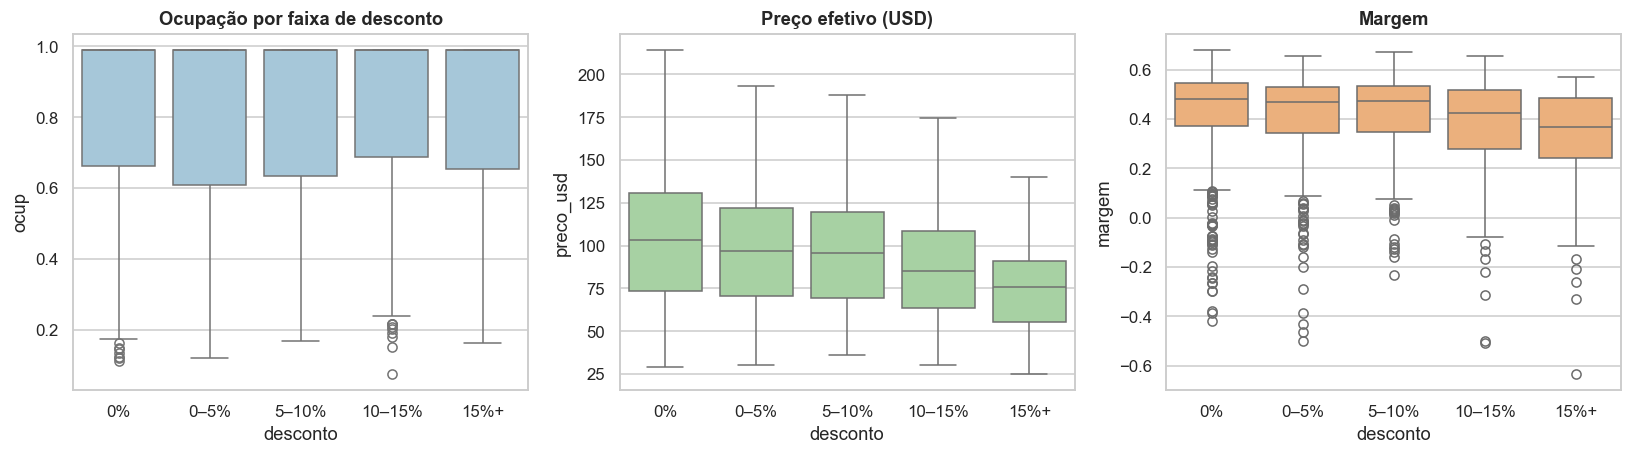

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
sns.boxplot(data=r, x='faixa_desc', y='ocup', ax=ax[0], color='#9ecae1'); ax[0].set_title('Ocupação por faixa de desconto'); ax[0].set_xlabel('desconto')
sns.boxplot(data=r, x='faixa_desc', y='preco_usd', ax=ax[1], color='#a1d99b'); ax[1].set_title('Preço efetivo (USD)'); ax[1].set_xlabel('desconto')
sns.boxplot(data=r, x='faixa_desc', y='margem', ax=ax[2], color='#fdae6b'); ax[2].set_title('Margem'); ax[2].set_xlabel('desconto')
plt.tight_layout(); plt.show()

In [14]:
print('Desconto -> ocupação (modelo da Q3):'); display(res.loc[['desconto_medio_pct']].round(5))
dm = r.dropna(subset=['seguidores_locais_milhoes']).copy()
m_mar = smf.ols('margem ~ desconto_medio_pct + ocup + log_seg + C(tipo_local) + C(padrao_producao) + C(regiao)', dm
               ).fit(cov_type='cluster', cov_kwds={'groups': dm.id_turne.factorize()[0]})
print(f'Desconto -> margem, controlando ocupação, demanda, local, produção e região (n={int(m_mar.nobs)}):')
display(pd.DataFrame({'coef': m_mar.params, 'IC95_inf': m_mar.conf_int()[0], 'IC95_sup': m_mar.conf_int()[1], 'p': m_mar.pvalues}).loc[['desconto_medio_pct']].round(5))

Desconto -> ocupação (modelo da Q3):


,coef,IC95_inf,IC95_sup,p
desconto_medio_pct,-0.001,-0.002,0.000,0.170


Desconto -> margem, controlando ocupação, demanda, local, produção e região (n=1811):


,coef,IC95_inf,IC95_sup,p
desconto_medio_pct,-0.003,-0.004,-0.002,0.000


**Leitura.** Descontos altos vêm com **preço efetivo menor e margem menor**, mas **sem ocupação maior** (a ocupação mediana é 0,99 em todas as faixas e o coeficiente do desconto sobre a ocupação é ≈ 0). Nestes dados o desconto não parece 'comprar' lotação; e, controlando ocupação, demanda, local, produção e região, cada ponto percentual de desconto se associa a ≈ −0,3 p.p. de margem (≈ −3 p.p. para 10% de desconto). *Alternativa:* descontos podem ser dados onde a demanda já era fraca (causalidade reversa); o modelo controla seguidores/engajamento, mas não tudo. *Risco de intervenção:* tirar o desconto num show de demanda fraca pode reduzir o público de um jeito que a associação não revela.

### Q5. Padrão de produção: premium compensa?

In [15]:
gp = r.groupby('padrao_producao')
pp = gp.agg(n=('margem','size'), custo_prod_mediano=('custo_producao_usd','median'), ocup_mediana=('ocup','median'),
        preco_usd_mediano=('preco_usd','median'), produtos_mediano=('receita_produtos_usd','median'),
        satisfacao_media=('satisfacao_publico_0a10','mean'), n_satisf=('satisfacao_publico_0a10','count'),
        margem_mediana=('margem','median'), lucro_mediano=('lucro_operacional_usd','median'))
pp['margem_agregada'] = gp.apply(lambda d: d.lucro_operacional_usd.sum()/d.receita_total_usd.sum(), include_groups=False)
display(pp.loc[['essencial','padrao','premium']].round(3))
print('Tipo de local por padrão (proporção por linha) — checagem de confusão:'); display(pd.crosstab(r.padrao_producao, r.tipo_local, normalize='index').round(3))

,n,custo_prod_mediano,ocup_mediana,preco_usd_mediano,produtos_mediano,satisfacao_media,n_satisf,margem_mediana,lucro_mediano,margem_agregada
padrao_producao,,,,,,,,,,
essencial,424,"29,549.150",0.990,92.971,"132,479.815",7.782,405,0.498,"551,628.495",0.523
padrao,1034,"44,019.275",0.990,97.269,"137,755.075",7.919,1001,0.471,"475,141.005",0.498
premium,420,"73,456.055",0.990,92.513,"139,140.900",8.129,408,0.403,"390,928.035",0.454


Tipo de local por padrão (proporção por linha) — checagem de confusão:


tipo_local,arena,estadio,teatro
padrao_producao,,,
essencial,0.682,0.108,0.210
padrao,0.681,0.108,0.211
premium,0.698,0.119,0.183


In [16]:
mp = smf.ols('margem ~ C(padrao_producao, Treatment("essencial")) + C(tipo_local) + C(regiao) + ocup + np.log(preco_usd)', r
            ).fit(cov_type='cluster', cov_kwds={'groups': r.id_turne.factorize()[0]})
print('Margem — efeito do padrão vs essencial (n = %d):' % mp.nobs)
display(pd.DataFrame({'coef': mp.params, 'IC95_inf': mp.conf_int()[0], 'IC95_sup': mp.conf_int()[1], 'p': mp.pvalues}).filter(like='padrao', axis=0).round(4))
rsat = r.dropna(subset=['satisfacao_publico_0a10'])
ms = smf.ols('satisfacao_publico_0a10 ~ C(padrao_producao, Treatment("essencial")) + C(tipo_local) + C(regiao)', rsat
            ).fit(cov_type='cluster', cov_kwds={'groups': rsat.id_turne.factorize()[0]})
print('Satisfação (0–10) — efeito do padrão vs essencial (n = %d):' % ms.nobs)
display(pd.DataFrame({'coef': ms.params, 'IC95_inf': ms.conf_int()[0], 'IC95_sup': ms.conf_int()[1], 'p': ms.pvalues}).filter(like='padrao', axis=0).round(4))
print('Spearman satisfação×margem:', round(stats.spearmanr(rsat.satisfacao_publico_0a10, rsat.margem)[0], 3), '(n=%d)' % len(rsat))

Margem — efeito do padrão vs essencial (n = 1878):


,coef,IC95_inf,IC95_sup,p
"C(padrao_producao, Treatment(""essencial""))[T.padrao]",-0.028,-0.040,-0.016,0.000
"C(padrao_producao, Treatment(""essencial""))[T.premium]",-0.090,-0.114,-0.066,0.000


Satisfação (0–10) — efeito do padrão vs essencial (n = 1814):


,coef,IC95_inf,IC95_sup,p
"C(padrao_producao, Treatment(""essencial""))[T.padrao]",0.133,0.040,0.226,0.005
"C(padrao_producao, Treatment(""essencial""))[T.premium]",0.345,0.229,0.462,0.000


Spearman satisfação×margem: 0.011 (n=1814)


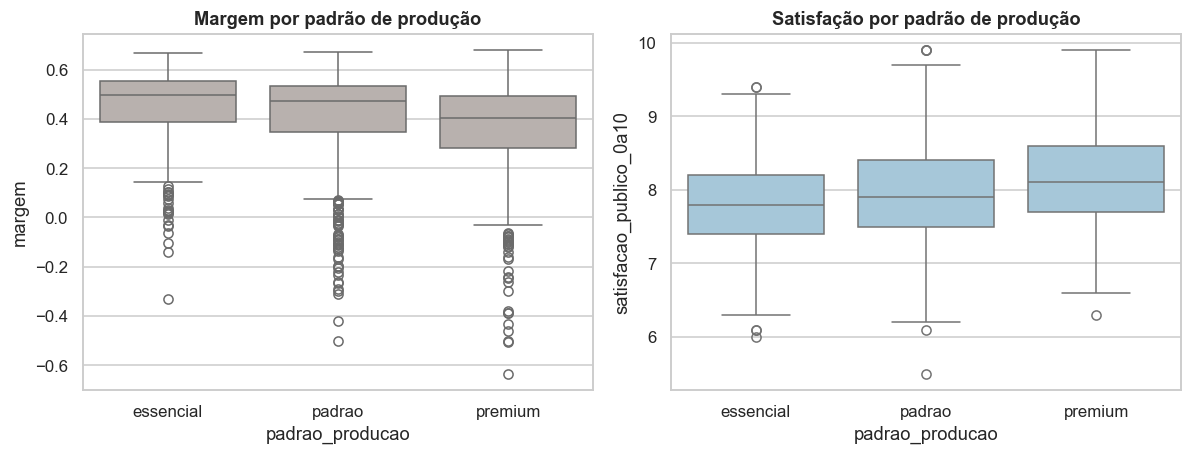

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3)); order = ['essencial','padrao','premium']
sns.boxplot(data=r, x='padrao_producao', y='margem', order=order, ax=ax[0], color='#bab0ac'); ax[0].set_title('Margem por padrão de produção')
sns.boxplot(data=r, x='padrao_producao', y='satisfacao_publico_0a10', order=order, ax=ax[1], color='#9ecae1'); ax[1].set_title('Satisfação por padrão de produção')
plt.tight_layout(); plt.show()

**Leitura.** O padrão se distribui de modo parecido entre tipos de local (sem confusão grande por tamanho). **Premium** custa bem mais em produção, **não eleva ocupação, preço nem venda de produtos** e reduz a margem em torno de 9 p.p. controlando local, região, ocupação e preço. O ganho aparece só na **satisfação (+~0,3 ponto)**, que quase não se associa à margem. *Alternativa:* a satisfação pode ter benefícios futuros (fidelização) que esta base de curto prazo não captura. *Risco:* reduzir a produção onde o premium sustenta a marca pode afetar demanda futura, o que a associação não mostra.

### Q6. Que outros fatores pré-evento e de contexto se associam à margem?

Correlação de Spearman com a margem (casos pareados por variável):


,rho,n
desconto_medio_pct,-0.138,1878
intervalo_show_anterior_dias,-0.094,1698
ordem_show_turne,-0.035,1878
antecedencia_venda_dias,-0.005,1878
dias_desde_lancamento,0.031,1878
engajamento_redes_pct,0.103,1878
capacidade,0.430,1878
streams_locais_30_dias_milhoes,0.488,1820
seguidores_locais_milhoes,0.653,1811


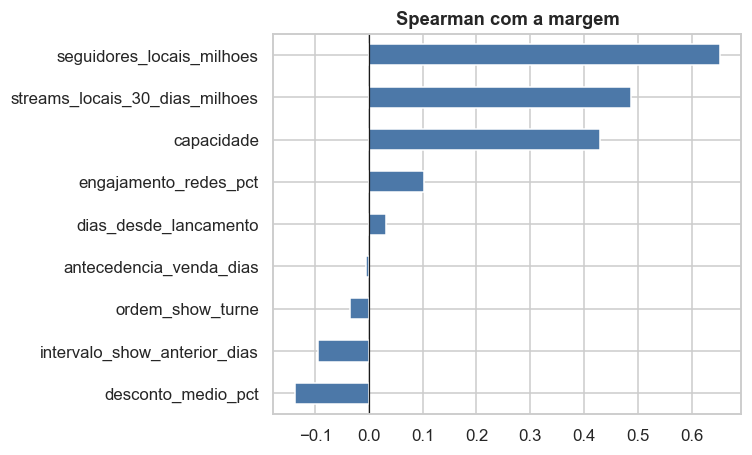

In [18]:
vars_pre = ['seguidores_locais_milhoes','streams_locais_30_dias_milhoes','engajamento_redes_pct','antecedencia_venda_dias','dias_desde_lancamento',
            'intervalo_show_anterior_dias','ordem_show_turne','capacidade','desconto_medio_pct']
cm = r[vars_pre + ['margem']].corr(method='spearman')['margem'].drop('margem').sort_values()
print('Correlação de Spearman com a margem (casos pareados por variável):')
display(pd.DataFrame({'rho': cm, 'n': [r[[v,'margem']].dropna().shape[0] for v in cm.index]}).round(3))
fig, ax = plt.subplots(figsize=(7, 4.3)); cm.plot.barh(ax=ax, color='#4C78A8'); ax.axvline(0, c='k', lw=.8); ax.set_title('Spearman com a margem'); plt.tight_layout(); plt.show()

In [19]:
use = ['margem','log_seg','engajamento_redes_pct','antecedencia_venda_dias','dias_desde_lancamento','desconto_medio_pct','ordem_show_turne',
       'tipo_local','padrao_producao','regiao','mesmo_pais_show_anterior','id_turne','grupo']
dm2 = r.dropna(subset=use).copy(); dm2['mesmo_pais'] = dm2.mesmo_pais_show_anterior.astype(int)
f = ('margem ~ log_seg + engajamento_redes_pct + antecedencia_venda_dias + dias_desde_lancamento + desconto_medio_pct'
     ' + ordem_show_turne + mesmo_pais + C(tipo_local) + C(padrao_producao) + C(regiao)')
for chave in ['id_turne','grupo']:
    mm = smf.ols(f, dm2).fit(cov_type='cluster', cov_kwds={'groups': dm2[chave].factorize()[0]})
    print(f'Erros clusterizados por {chave}: n={int(mm.nobs)}, R²={mm.rsquared:.3f}, clusters={dm2[chave].nunique()}')
    display(pd.DataFrame({'coef': mm.params, 'IC95_inf': mm.conf_int()[0], 'IC95_sup': mm.conf_int()[1], 'p': mm.pvalues}).drop('Intercept').round(4))

Erros clusterizados por id_turne: n=1811, R²=0.591, clusters=180


,coef,IC95_inf,IC95_sup,p
C(tipo_local)[T.estadio],-0.066,-0.086,-0.047,0.000
C(tipo_local)[T.teatro],-0.161,-0.183,-0.140,0.000
C(padrao_producao)[T.padrao],-0.024,-0.037,-0.012,0.000
C(padrao_producao)[T.premium],-0.090,-0.112,-0.068,0.000
C(regiao)[T.America do Norte],0.073,0.052,0.095,0.000
C(regiao)[T.Asia],0.024,0.002,0.045,0.030
C(regiao)[T.Europa],0.045,0.027,0.064,0.000
log_seg,0.179,0.161,0.197,0.000
engajamento_redes_pct,0.014,0.010,0.018,0.000
antecedencia_venda_dias,-0.000,-0.000,0.000,0.711


Erros clusterizados por grupo: n=1811, R²=0.591, clusters=20


,coef,IC95_inf,IC95_sup,p
C(tipo_local)[T.estadio],-0.066,-0.099,-0.034,0.000
C(tipo_local)[T.teatro],-0.161,-0.182,-0.141,0.000
C(padrao_producao)[T.padrao],-0.024,-0.038,-0.011,0.000
C(padrao_producao)[T.premium],-0.090,-0.127,-0.053,0.000
C(regiao)[T.America do Norte],0.073,0.044,0.103,0.000
C(regiao)[T.Asia],0.024,0.009,0.039,0.002
C(regiao)[T.Europa],0.045,0.022,0.069,0.000
log_seg,0.179,0.153,0.204,0.000
engajamento_redes_pct,0.014,0.008,0.021,0.000
antecedencia_venda_dias,-0.000,-0.000,0.000,0.730


**Leitura.** Controlando o resto, a **base de seguidores local** (pré-evento) é o preditor mais forte da margem (ρ de Spearman 0,65 sozinha); **teatro** (≈ −16 p.p. vs arena), **padrão premium** (≈ −9 p.p.) e **desconto** (≈ −0,3 p.p. por ponto) a reduzem; o **estádio**, uma vez controlada a demanda, fica ≈ −7 p.p. abaixo da arena na média; a **América do Norte** tem margem ≈ +7 p.p. acima da América Latina; shows mais tarde na turnê (≈ −0,2 p.p. por posição) e *não* mudar de país (+1,6 p.p.) têm efeitos pequenos. Antecedência de venda e dias desde o lançamento **não** distinguem a margem. O padrão se mantém ao clusterizar por grupo (menos clusters, intervalos mais largos).

### Q7. Agregando por grupo e por turnê: o padrão se mantém?

,shows,lucro_total_M,receita_M,margem_agregada,seguidores_med,pct_estadio,pct_premium,ocup_mediana
grupo,,,,,,,,
Stray Kids,93,100.301,177.655,0.565,14.560,0.110,0.000,0.990
TOMORROW X TOGETHER,94,123.605,221.008,0.559,11.255,0.181,0.000,0.990
ATEEZ,92,95.087,174.222,0.546,13.655,0.124,0.225,0.990
SEVENTEEN,102,119.721,220.866,0.542,14.220,0.109,0.465,0.990
TWICE,86,72.896,135.771,0.537,12.765,0.071,0.000,0.990
(G)I-DLE,104,93.500,178.991,0.522,10.345,0.173,0.106,0.978
IVE,98,75.534,147.513,0.512,10.115,0.144,0.330,0.990
MONSTA X,103,73.088,146.913,0.497,7.450,0.119,0.356,0.990
LE SSERAFIM,85,61.555,125.446,0.491,8.470,0.224,0.494,0.909


Spearman entre grupos (n=20):


,rho com margem
margem_agregada,1.000
seguidores_med,0.950
pct_estadio,0.540
pct_premium,-0.140
ocup_mediana,0.430


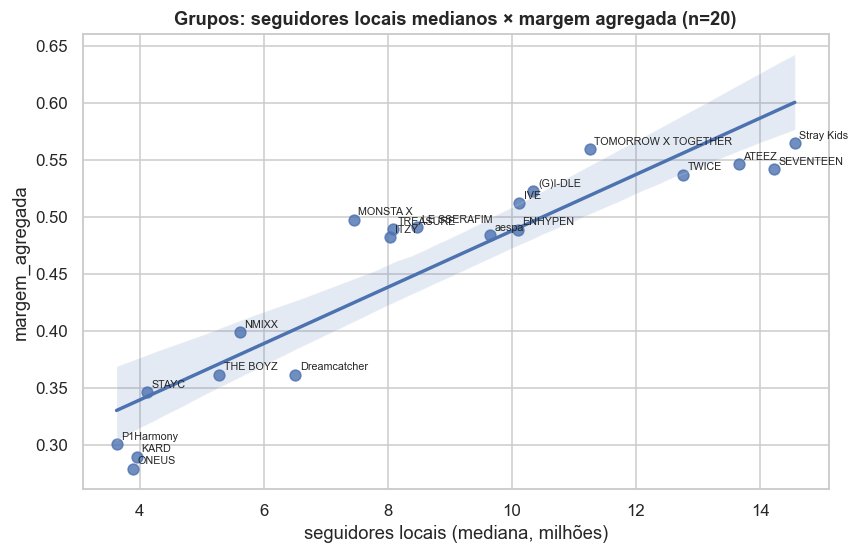

In [20]:
g = k.groupby('grupo').agg(shows=('id_show','size'), lucro_total_M=('lucro_operacional_usd', lambda s: s.sum()/1e6), receita_M=('receita_total_usd', lambda s: s.sum()/1e6))
g['margem_agregada'] = g.lucro_total_M / g.receita_M
g['seguidores_med'] = r.groupby('grupo').seguidores_locais_milhoes.median()
g['pct_estadio'] = r.groupby('grupo').apply(lambda d: (d.tipo_local=='estadio').mean(), include_groups=False)
g['pct_premium'] = r.groupby('grupo').apply(lambda d: (d.padrao_producao=='premium').mean(), include_groups=False)
g['ocup_mediana'] = r.groupby('grupo').ocup.median()
g = g.sort_values('margem_agregada', ascending=False)
display(g.round(3))
print('Spearman entre grupos (n=20):'); display(g[['margem_agregada','seguidores_med','pct_estadio','pct_premium','ocup_mediana']].corr(method='spearman')['margem_agregada'].round(2).to_frame('rho com margem'))
fig, ax = plt.subplots(figsize=(8, 5.2)); sns.regplot(data=g, x='seguidores_med', y='margem_agregada', ax=ax, scatter_kws={'s': 50})
for n_, row in g.iterrows(): ax.annotate(n_, (row.seguidores_med, row.margem_agregada), fontsize=7, xytext=(3, 3), textcoords='offset points')
ax.set_title('Grupos: seguidores locais medianos × margem agregada (n=20)'); ax.set_xlabel('seguidores locais (mediana, milhões)'); plt.tight_layout(); plt.show()

In [21]:
tm = r.groupby('id_turne').agg(seg=('seguidores_locais_milhoes','median'), pct_estadio=('tipo_local', lambda s: (s=='estadio').mean()),
        pct_premium=('padrao_producao', lambda s: (s=='premium').mean()), desc=('desconto_medio_pct','mean'),
        lucro=('lucro_operacional_usd','sum'), receita=('receita_total_usd','sum')).dropna()
tm['margem'] = tm.lucro / tm.receita
print('Turnês (n = %d), Spearman com a margem da turnê:' % len(tm))
display(tm[['seg','pct_estadio','pct_premium','desc','margem']].corr(method='spearman')['margem'].drop('margem').round(3).to_frame('rho'))

Turnês (n = 180), Spearman com a margem da turnê:


,rho
seg,0.883
pct_estadio,0.278
pct_premium,-0.252
desc,-0.096


**Leitura.** Em nível de grupo (n=20) e de turnê, quem tem base de seguidores maior tem margem agregada maior (ρ≈0,95 entre os 20 grupos; ρ≈0,88 entre as 180 turnês) — a mesma direção dos shows individuais. Premium não aparece como diferencial positivo (ρ≈−0,14 nos grupos; −0,25 nas turnês). Com 20 grupos as correlações são frágeis. *Alternativa:* grupos grandes também têm mais patrocínio, contratos e preços maiores; "seguidores" é um marcador de demanda, não uma alavanca simples.

## 4. Insights, ações propostas e como avaliar cada uma
**Insight 1 — Dimensionar o local pela demanda.** Estádios em mercados de demanda baixa operam com ocupação mediana ~22% e margem mediana ~20% (vs. ~38% em arenas; n=47 estádios); em demanda alta, estádio e arena se equivalem. Teatros enchem, mas ficam em ~23–34%.
- **Ação 1:** em mercados com poucos seguidores/engajamento, usar **arena (ou 2 noites em arena) em vez de estádio**; reservar estádio para mercados de alta demanda.
- **Como avaliar:** piloto por mercado em turnês similares; comparar **margem, ocupação e lucro por show** entre os formatos, com n por braço e IC; checar se a arena não bate no teto de 99% (demanda reprimida).
- **Risco:** a associação pode refletir seleção (quem escolheu estádio sabia algo que não medimos) e pode não se manter ao intervir.

**Insight 2 — Premium não se paga no curto prazo.** Premium custa bem mais em produção e reduz a margem em ~9 p.p., sem ganho em ocupação, preço ou venda de produtos; só a satisfação sobe levemente.
- **Ação 2:** adotar **essencial/padrão como base** e usar premium só em **datas-âncora** (p. ex. mercados de maior demanda), como teste.
- **Como avaliar:** comparar margem, ocupação e satisfação entre premium e padrão em locais e mercados equivalentes; checar se a satisfação se converte em compras futuras (fora deste dataset).
- **Risco:** efeitos de marca e fidelização futura não aparecem aqui.

**Insight 3 — Descontos fortes erodem preço sem encher o local.** Descontos >10% reduzem preço e margem (mediana 0,48 sem desconto vs 0,37 na faixa 15%+), a ocupação mediana permanece em 99% em todas as faixas e o efeito do desconto sobre a ocupação é ≈ 0.
- **Ação 3:** **limitar o desconto médio a ≤10%** e reservar descontos maiores a shows com ocupação projetada baixa.
- **Como avaliar:** teste randomizado de desconto por data/mercado; medir ocupação, preço efetivo e margem; sucesso = margem ≥ controle sem queda relevante de ocupação.
- **Risco:** se o desconto era dado onde a demanda era fraca, retirá-lo pode reduzir o público; a associação não prova o efeito.

**Insight 4 (contexto) — Cancelamentos são raros e pouco materiais.** 24 shows (1,3%) custaram ~US$ 3,4 M (~0,3% do lucro). O foco deve ir para a estrutura de receita/custo, não para cancelamentos, salvo se houver padrão causal (não identificável com n=24).

## 5. Limitações
- **Associação ≠ causalidade.** As recomendações envolvem variáveis manipuláveis (tipo de local, padrão de produção, desconto); a associação pode não se manter ao intervir. Por isso cada ação vem com um teste proposto.
- **Dependência entre observações:** shows da mesma turnê e do mesmo grupo não são independentes. Usei erros-padrão clusterizados e agregações por turnê/grupo; com 20 grupos a inferência em nível de grupo é frágil.
- **Dados simulados**, sem calibração histórica: os resultados descrevem o *cenário*, não a realidade.
- **Escopo:** só a operação de shows (sem streaming, discos, licenciamento, custos corporativos); o repasse aos artistas é custo da operação, não prejuízo dos artistas.
- **Ausentes:** seguidores e streams (3–4%) e satisfação (~5%) têm dados faltantes possivelmente não aleatórios; usei casos completos e informei n.
- **Ocupação censurada em 99%** limita a leitura de efeitos em shows lotados. O lucro é recalculável pela contabilidade (não é uma descoberta); o foco foi em fatores prévios e na composição.